In [3]:
import pandas as pd
train_df = pd.read_csv("/content/drive/MyDrive/projet covid radiographie pulmonaire/train.csv")
val_df = pd.read_csv("/content/drive/MyDrive/projet covid radiographie pulmonaire/validation.csv")
test_df = pd.read_csv("/content/drive/MyDrive/projet covid radiographie pulmonaire/test.csv")

In [52]:
# Étape 1 : Préparation des DataGenerators pour le modèle CNN avec suréchantillonnage

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configuration des dimensions et hyperparamètres
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32

# S'assurer que les targets sont bien en chaînes de caractères pour le mode 'binary' de flow_from_dataframe
train_df_resampled['target_str'] = train_df_resampled['target'].astype(str)
val_gen_df['target_str'] = val_gen_df['target'].astype(str)
test_df['target_str'] = test_df['target'].astype(str)

# Définition des augmentations de données pour l'entraînement
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)


val_test_datagen = ImageDataGenerator(rescale=1./255)

# Générateurs de données
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df_resampled,
    x_col='filepath',
    y_col='target_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 16306 validated image filenames belonging to 2 classes.
Found 2186 validated image filenames belonging to 2 classes.
Found 2762 validated image filenames belonging to 2 classes.


In [54]:
# Étape 2 : Définition de l'architecture du modèle CNN

In [55]:
from tensorflow.keras import layers, models

def build_cnn_model():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),
        
        # Premier bloc de convolution
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Deuxième bloc
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Troisième bloc
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Couches de classification dense
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model = build_cnn_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,393 (49.36 MB)

 Trainable params: 12,938,689 (49.36 MB)

 Non-trainable params: 704 (2.75 KB)

In [56]:
# Étape 3 : Entraînement du modèle avec Callbacks

In [57]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Chemins de sauvegarde
checkpoint_filepath = '/content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_oversampling.keras'

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_filepath,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Entraînement du modèle
epochs = 5

history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 1/5
510/510 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7248 - auc: 0.7964 - loss: 0.6123
Epoch 1: val_loss improved from None to 1.14297, saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_oversampling.keras

Epoch 1: finished saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_oversampling.keras
510/510 ━━━━━━━━━━━━━━━━━━━━ 3396s 7s/step - accuracy: 0.7586 - auc: 0.8397 - loss: 0.5179 - val_accuracy: 0.4263 - val_auc: 0.7100 - val_loss: 1.1430
Epoch 2/5
510/510 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8284 - auc: 0.9099 - loss: 0.3826
Epoch 2: val_loss improved from 1.14297 to 0.35793, saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_oversampling.keras

Epoch 2: finished saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_oversampling.keras
510/510 ━━━━━━━━━━━━━━━━━━━━ 3318s 7s/step - accuracy: 0.8379 - auc: 0.918

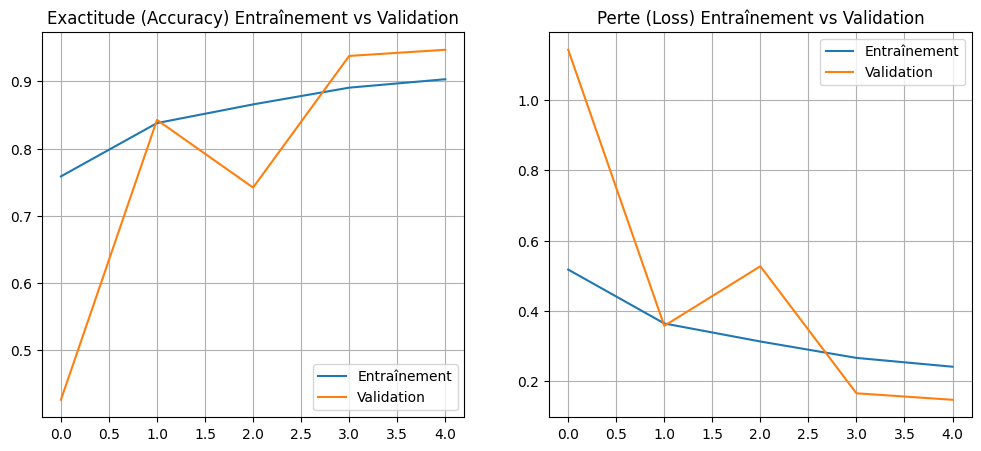

In [58]:
import matplotlib.pyplot as plt

# Récupération des historiques de métriques
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Graphique d'accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entraînement')
plt.plot(epochs_range, val_acc, label='Validation')
plt.legend(loc='lower right')
plt.title('Exactitude (Accuracy) Entraînement vs Validation')
plt.grid(True)

# Graphique de perte
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entraînement')
plt.plot(epochs_range, val_loss, label='Validation')
plt.legend(loc='upper right')
plt.title('Perte (Loss) Entraînement vs Validation')
plt.grid(True)

plt.show()

In [ ]:
# Étape 4 : Évaluation du modèle avec Oversampling sur l'ensemble de validation

87/87 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step

--- RAPPORT DE CLASSIFICATION ---
              precision    recall  f1-score   support

   NON-COVID       0.98      0.96      0.97      2039
       COVID       0.89      0.94      0.91       723

    accuracy                           0.95      2762
   macro avg       0.93      0.95      0.94      2762
weighted avg       0.95      0.95      0.95      2762



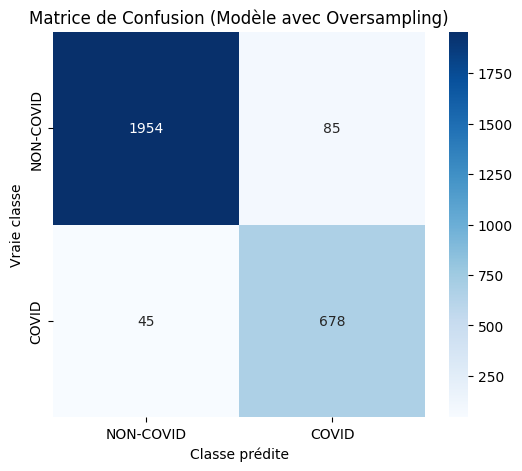

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.load_weights(checkpoint_filepath)


val_generator.reset()
y_pred_probs = model.predict(val_generator, verbose=1)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()


y_true = val_generator.classes

# 4. Rapport de classification
print("\n--- RAPPORT DE CLASSIFICATION ---")
print(classification_report(y_true, y_pred, target_names=['NON-COVID', 'COVID']))

# 5. Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['NON-COVID', 'COVID'], 
    yticklabels=['NON-COVID', 'COVID']
)
plt.title('Matrice de Confusion (Modèle avec Oversampling)')
plt.ylabel('Vraie classe')
plt.xlabel('Classe prédite')
plt.show()

In [ ]:
# Étape 5 : Heatmap détaillée de la Matrice de Confusion

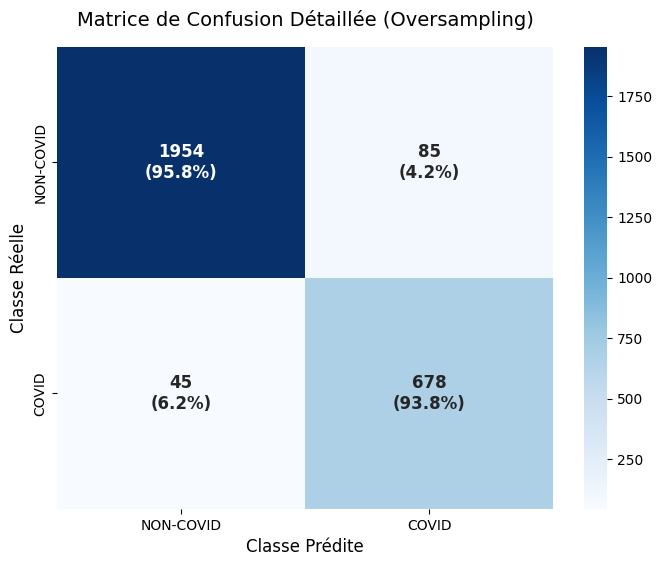

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcul des proportions (pourcentages par rapport aux vraies classes)
cm_percentage = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# Configuration de la figure
plt.figure(figsize=(8, 6))

# Création de labels combinant le nombre brut et le pourcentage
labels = [
    f"{val}\n({pct:.1f}%)" 
    for val, pct in zip(cm.flatten(), cm_percentage.flatten())
]
labels = np.asarray(labels).reshape(2, 2)

# Affichage de la heatmap
sns.heatmap(
    cm, 
    annot=labels, 
    fmt='', 
    cmap='Blues', 
    cbar=True,
    xticklabels=['NON-COVID', 'COVID'], 
    yticklabels=['NON-COVID', 'COVID'],
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title('Matrice de Confusion Détaillée (Oversampling)', fontsize=14, pad=15)
plt.ylabel('Classe Réelle', fontsize=12)
plt.xlabel('Classe Prédite', fontsize=12)
plt.show()

In [ ]:
# Étape 6 : Configuration des Générateurs de Données avec Data Augmentation et Oversampling

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dimensions cibles des images et taille du batch
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32

# S'assurer que les étiquettes cibles sont au format chaîne de caractères pour flow_from_dataframe (mode binary)
train_df_resampled['target_str'] = train_df_resampled['target'].astype(str)
val_gen_df['target_str'] = val_gen_df['target'].astype(str)
test_df['target_str'] = test_df['target'].astype(str)

# Définition de l'augmentation de données (Data Augmentation) pour l'entraînement (oversampled)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)


val_test_datagen = ImageDataGenerator(rescale=1./255)

# Générateur d'entraînement combinant Oversampling et Data Augmentation
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df_resampled,
    x_col='filepath',
    y_col='target_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Générateur de validation
val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Générateur de test
test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 16306 validated image filenames belonging to 2 classes.
Found 2186 validated image filenames belonging to 2 classes.
Found 2762 validated image filenames belonging to 2 classes.


In [65]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Recréer une instance fraîche du modèle pour l'entraînement
model_augmented = build_cnn_model()

# Définir le chemin de sauvegarde pour cette configuration
checkpoint_filepath_augmented = '/content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_aug_and_oversampling.keras'

callbacks_augmented = [
    EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_filepath_augmented,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Lancer l'entraînement pour 5 époques
history_augmented = model_augmented.fit(
    train_generator,
    epochs=5,
    validation_data=val_generator,
    callbacks=callbacks_augmented
)

Epoch 1/5
510/510 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7336 - auc: 0.8097 - loss: 0.5847
Epoch 1: val_loss improved from None to 1.48535, saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_aug_and_oversampling.keras

Epoch 1: finished saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_aug_and_oversampling.keras
510/510 ━━━━━━━━━━━━━━━━━━━━ 3327s 7s/step - accuracy: 0.7657 - auc: 0.8469 - loss: 0.5061 - val_accuracy: 0.2859 - val_auc: 0.8148 - val_loss: 1.4854
Epoch 2/5
510/510 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8071 - auc: 0.8889 - loss: 0.4226
Epoch 2: val_loss improved from 1.48535 to 0.45128, saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_aug_and_oversampling.keras

Epoch 2: finished saving model to /content/drive/My Drive/projet covid radiographie pulmonaire/best_cnn_with_aug_and_oversampling.keras
510/510 ━━━━━━━━━━━━━━━━━━━━ 3331s 7s/step

In [ ]:
# Étape 7 : Évaluation du Modèle Final (Augmentation + Oversampling) sur l'ensemble de validation

87/87 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step

--- RAPPORT DE CLASSIFICATION (AVEC AUGMENTATION + OVERSAMPLING) ---
              precision    recall  f1-score   support

   NON-COVID       0.93      0.99      0.96      2039
       COVID       0.96      0.78      0.86       723

    accuracy                           0.94      2762
   macro avg       0.94      0.89      0.91      2762
weighted avg       0.94      0.94      0.93      2762



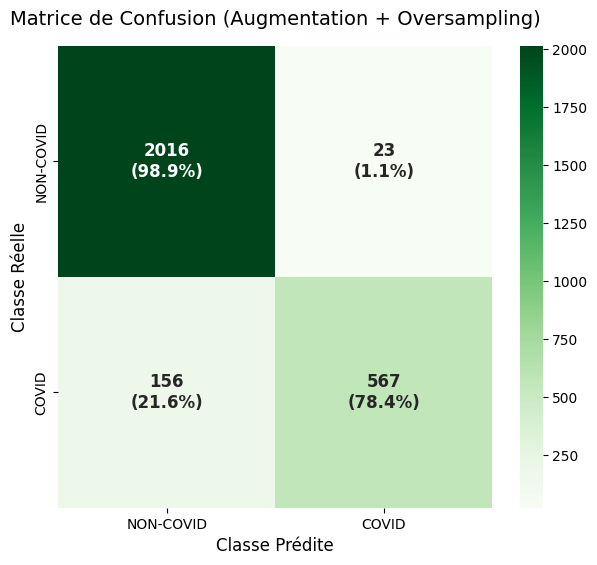

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Charger les meilleurs poids sauvegardés
model_augmented.load_weights(checkpoint_filepath_augmented)


val_generator.reset()
y_pred_probs_aug = model_augmented.predict(val_generator, verbose=1)
y_pred_aug = (y_pred_probs_aug > 0.5).astype(int).flatten()

# Obtenir les vraies étiquettes
y_true_aug = val_generator.classes

# Rapport de classification
print("\n--- RAPPORT DE CLASSIFICATION (AVEC AUGMENTATION + OVERSAMPLING) ---")
print(classification_report(y_true_aug, y_pred_aug, target_names=['NON-COVID', 'COVID']))

# Calcul de la matrice de confusion
cm_aug = confusion_matrix(y_true_aug, y_pred_aug)
cm_percentage_aug = cm_aug.astype('float') / cm_aug.sum(axis=1)[:, np.newaxis] * 100

# Labels personnalisés
labels_aug = [
    f"{val}\n({pct:.1f}%)"
    for val, pct in zip(cm_aug.flatten(), cm_percentage_aug.flatten())
]
labels_aug = np.asarray(labels_aug).reshape(2, 2)

# Affichage de la Heatmap
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_aug,
    annot=labels_aug,
    fmt='',
    cmap='Greens',
    xticklabels=['NON-COVID', 'COVID'],
    yticklabels=['NON-COVID', 'COVID'],
    annot_kws={"size": 12, "weight": "bold"}
)
plt.title('Matrice de Confusion (Augmentation + Oversampling)', fontsize=14, pad=15)
plt.ylabel('Classe Réelle', fontsize=12)
plt.xlabel('Classe Prédite', fontsize=12)
plt.show()

In [ ]:
# Étape 8 : Visualisation des courbes d'apprentissage (Augmentation + Oversampling)

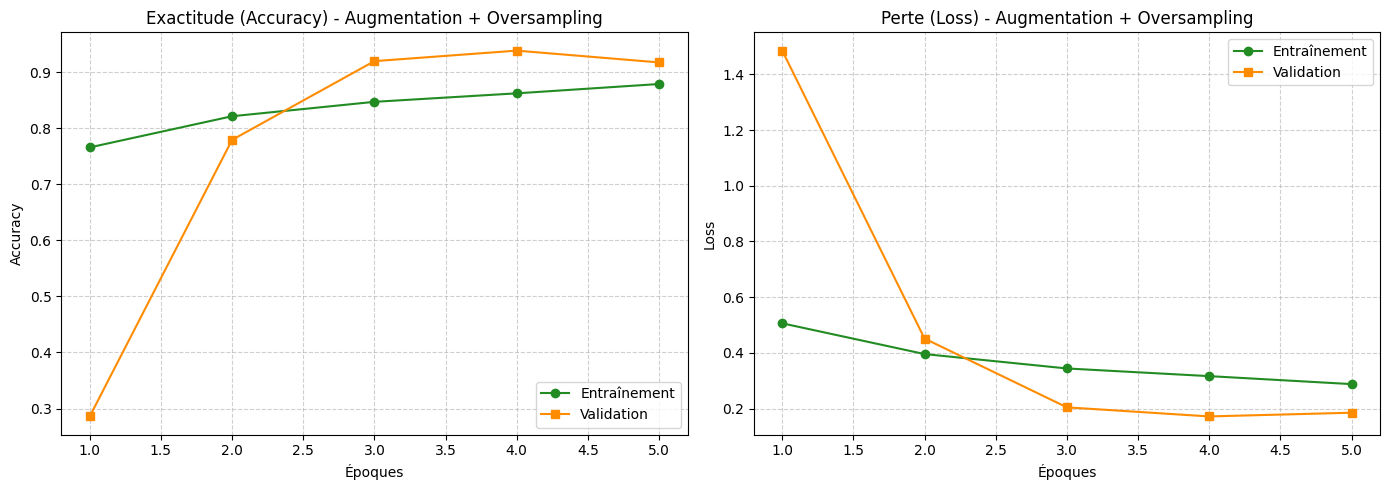

In [68]:
import matplotlib.pyplot as plt

# Récupération des historiques de métriques pour le modèle augmenté
acc_aug = history_augmented.history['accuracy']
val_acc_aug = history_augmented.history['val_accuracy']
loss_aug = history_augmented.history['loss']
val_loss_aug = history_augmented.history['val_loss']

epochs_range = range(1, len(acc_aug) + 1)

plt.figure(figsize=(14, 5))

# Graphique d'exactitude (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_aug, 'o-', label='Entraînement', color='forestgreen')
plt.plot(epochs_range, val_acc_aug, 's-', label='Validation', color='darkorange')
plt.title('Exactitude (Accuracy) - Augmentation + Oversampling', fontsize=12)
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')

# Graphique de perte (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_aug, 'o-', label='Entraînement', color='forestgreen')
plt.plot(epochs_range, val_loss_aug, 's-', label='Validation', color='darkorange')
plt.title('Perte (Loss) - Augmentation + Oversampling', fontsize=12)
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
# Étape 9 : Comparaison des Courbes d'Apprentissage (Avec vs Sans Data Augmentation)

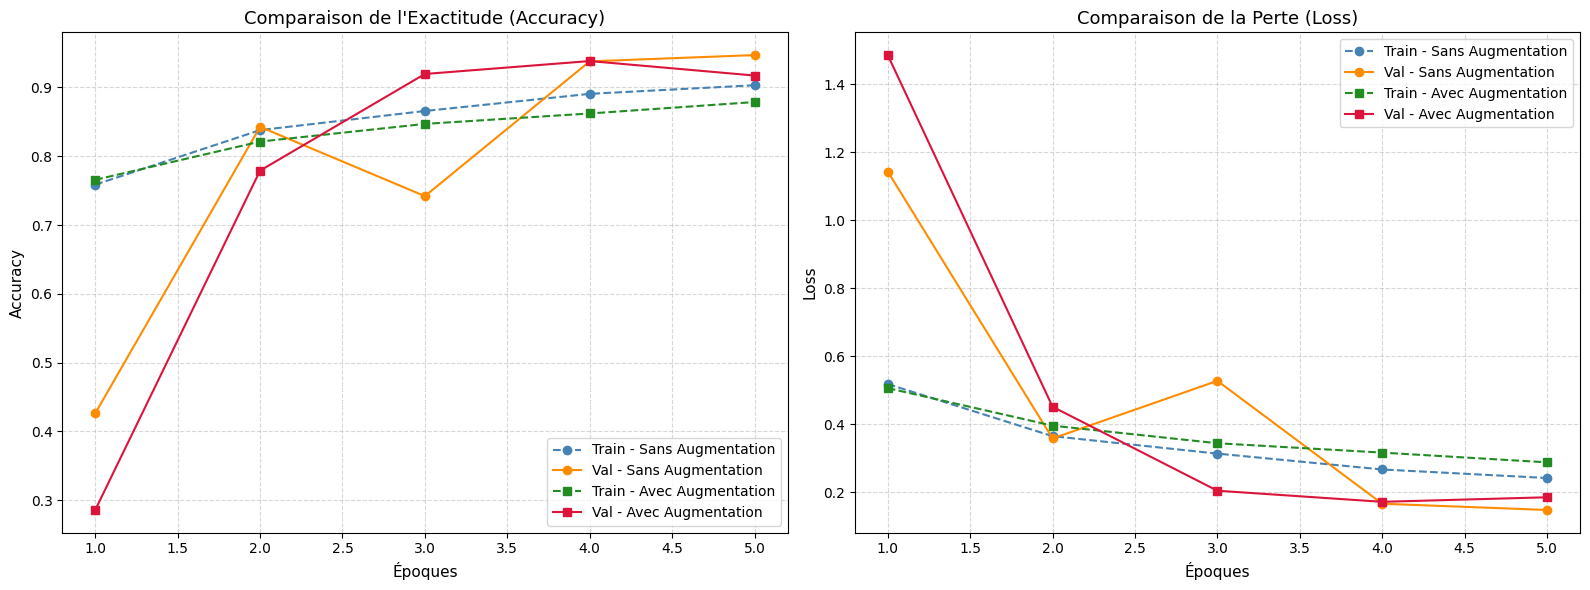

In [69]:
import matplotlib.pyplot as plt

# Extraction des métriques pour les deux configurations
epochs_range_simple = range(1, len(history.history['accuracy']) + 1)
epochs_range_aug = range(1, len(history_augmented.history['accuracy']) + 1)

plt.figure(figsize=(16, 6))

# 1. Comparaison des Exactitudes (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range_simple, history.history['accuracy'], 'o--', label='Train - Sans Augmentation', color='steelblue')
plt.plot(epochs_range_simple, history.history['val_accuracy'], 'o-', label='Val - Sans Augmentation', color='darkorange')
plt.plot(epochs_range_aug, history_augmented.history['accuracy'], 's--', label='Train - Avec Augmentation', color='forestgreen')
plt.plot(epochs_range_aug, history_augmented.history['val_accuracy'], 's-', label='Val - Avec Augmentation', color='crimson')

plt.title('Comparaison de l\'Exactitude (Accuracy)', fontsize=13)
plt.xlabel('Époques', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=10)

# 2. Comparaison des Pertes (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range_simple, history.history['loss'], 'o--', label='Train - Sans Augmentation', color='steelblue')
plt.plot(epochs_range_simple, history.history['val_loss'], 'o-', label='Val - Sans Augmentation', color='darkorange')
plt.plot(epochs_range_aug, history_augmented.history['loss'], 's--', label='Train - Avec Augmentation', color='forestgreen')
plt.plot(epochs_range_aug, history_augmented.history['val_loss'], 's-', label='Val - Avec Augmentation', color='crimson')

plt.title('Comparaison de la Perte (Loss)', fontsize=13)
plt.xlabel('Époques', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()